# Predicting Remaining Useful Life (RUL) of Jet Engines
**CSC1181 Machine Learning Project**

Dataset: NASA C-MAPSS, subsets FD001 and FD003.

Goal:
1. Predict how many cycles (flights) an engine has left before it fails (**RUL**). This is a **regression** problem.
2. Predict if an engine will fail in the next 30 cycles (yes / no). This is a **classification** problem.

Models used: mean baseline, linear regression, decision tree (regression) and logistic regression (classification).

## 0. Get the project files (only needed in Google Colab)
If you opened this notebook in Colab from GitHub, Colab only has the notebook, not the other files
(erp.py, app.py, dashboard.html ...). This cell downloads the whole project from GitHub.
On your own computer this cell does nothing.

In [ ]:
import os

GITHUB_URL = "https://github.com/weeblul/rul-maintenence-Project-Stats.git"

# check if we are running in Google Colab
try:
    import google.colab
    in_colab = True
except ImportError:
    in_colab = False

if in_colab and not os.path.exists("erp.py"):
    folder = GITHUB_URL.split("/")[-1].replace(".git", "")
    if not os.path.exists(folder):
        os.system("git clone " + GITHUB_URL)
    if os.path.exists(folder):
        os.chdir(folder)
    else:
        print("Could not download the project. Check GITHUB_URL.")

print("Working folder:", os.getcwd())

## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

## 2. Load the data
Each file has 26 columns separated by spaces: engine number, cycle number, 3 operating settings and 21 sensors.
The files have no column names so I add them myself.

In [ ]:
column_names = ["unit", "cycle", "setting1", "setting2", "setting3"]
for i in range(1, 22):
    column_names.append("s" + str(i))

print(column_names)

['unit', 'cycle', 'setting1', 'setting2', 'setting3', 's1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21']


### 2.1 Upload the data files
The NASA files are not in the GitHub repository, so you choose them from your own computer.
You need 6 files: `train_FD001.txt`, `train_FD003.txt`, `test_FD001.txt`, `test_FD003.txt`,
`RUL_FD001.txt` and `RUL_FD003.txt` (you can also upload the whole `CMAPSSData.zip`).
They are saved in the `data` folder. If a file is missing, the cell asks again.

In [ ]:
import os
import zipfile

needed = ["train_FD001.txt", "train_FD003.txt", "test_FD001.txt",
          "test_FD003.txt", "RUL_FD001.txt", "RUL_FD003.txt"]
os.makedirs("data", exist_ok=True)

def missing_files():
    missing = []
    for name in needed:
        if not os.path.exists(os.path.join("data", name)):
            missing.append(name)
    return missing

try:
    from google.colab import files
    in_colab = True
except ImportError:
    in_colab = False

while len(missing_files()) > 0:
    print("Missing files:", missing_files())

    if not in_colab:
        print("Copy the files into the 'data' folder next to this notebook, then run this cell again.")
        break

    print("Choose the files from your computer (you can select several at once, or CMAPSSData.zip).")
    uploaded = files.upload()
    if len(uploaded) == 0:
        print("No file chosen. Run this cell again when you are ready.")
        break

    for name in uploaded:
        content = uploaded[name]
        if name.endswith(".zip"):
            # take the 6 files we need out of the zip
            with open("upload.zip", "wb") as f:
                f.write(content)
            with zipfile.ZipFile("upload.zip") as z:
                for inside in z.namelist():
                    short_name = os.path.basename(inside)
                    if short_name in needed:
                        with open(os.path.join("data", short_name), "wb") as f:
                            f.write(z.read(inside))
            os.remove("upload.zip")
        elif name in needed:
            with open(os.path.join("data", name), "wb") as f:
                f.write(content)
        else:
            print("Skipped", name, "(not one of the 6 files)")
        # Colab also saves a copy next to the notebook, we only keep the one in data/
        if os.path.exists(name):
            os.remove(name)

if len(missing_files()) == 0:
    print("All 6 data files are in the data folder.")

In [ ]:
# read the training and test files for FD001 and FD003 (from the data folder)
train1 = pd.read_csv("data/train_FD001.txt", sep=r"\s+", header=None, names=column_names)
train3 = pd.read_csv("data/train_FD003.txt", sep=r"\s+", header=None, names=column_names)
test1 = pd.read_csv("data/test_FD001.txt", sep=r"\s+", header=None, names=column_names)
test3 = pd.read_csv("data/test_FD003.txt", sep=r"\s+", header=None, names=column_names)

# true RUL for the last cycle of every test engine
rul1 = pd.read_csv("data/RUL_FD001.txt", header=None, names=["true_RUL"])
rul3 = pd.read_csv("data/RUL_FD003.txt", header=None, names=["true_RUL"])

print("train FD001:", train1.shape)
print("train FD003:", train3.shape)
print("test FD001:", test1.shape)
print("test FD003:", test3.shape)

train FD001: (20631, 26)
train FD003: (24720, 26)
test FD001: (13096, 26)
test FD003: (16596, 26)


Both datasets use engine numbers 1 to 100, so I add a `dataset` column and make a new `engine` id like "FD001_1",
otherwise engine 1 from FD001 and engine 1 from FD003 would be mixed up.

In [ ]:
train1["dataset"] = "FD001"
train3["dataset"] = "FD003"
test1["dataset"] = "FD001"
test3["dataset"] = "FD003"

# stick the two datasets together
train = pd.concat([train1, train3])
test = pd.concat([test1, test3])

train["engine"] = train["dataset"] + "_" + train["unit"].astype(str)
test["engine"] = test["dataset"] + "_" + test["unit"].astype(str)

print("Training rows:", len(train), " engines:", train["engine"].nunique())
print("Test rows:", len(test), " engines:", test["engine"].nunique())
train.head()

Training rows: 45351  engines: 200
Test rows: 29692  engines: 200


,unit,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s14,s15,s16,s17,s18,s19,s20,s21,dataset,engine
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,FD001,FD001_1
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,FD001,FD001_1
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,FD001,FD001_1
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,FD001,FD001_1
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,FD001,FD001_1


## 3. Make the target variable (RUL)
In the training data every engine runs until it fails, so the last cycle of each engine is the failure point.

**RUL = last cycle of the engine − current cycle**

In [ ]:
# find the last cycle of every engine
max_cycle = train.groupby("engine")["cycle"].max()
max_cycle = max_cycle.reset_index()
max_cycle.columns = ["engine", "max_cycle"]

train = train.merge(max_cycle, on="engine")
train["RUL"] = train["max_cycle"] - train["cycle"]

train[["engine", "cycle", "max_cycle", "RUL"]].head()

# For the test data NASA gives the true RUL only at the last cycle of each engine (in the RUL files).
# So RUL at any row = (last cycle − current cycle) + true RUL at the end.

,engine,cycle,max_cycle,RUL
0,FD001_1,1,192,191
1,FD001_1,2,192,190
2,FD001_1,3,192,189
3,FD001_1,4,192,188
4,FD001_1,5,192,187


In [ ]:
# true RUL at the end of each test engine
rul1["engine"] = "FD001_" + (rul1.index + 1).astype(str)
rul3["engine"] = "FD003_" + (rul3.index + 1).astype(str)
rul_end = pd.concat([rul1, rul3])

test_max = test.groupby("engine")["cycle"].max().reset_index()
test_max.columns = ["engine", "max_cycle"]

test = test.merge(test_max, on="engine")
test = test.merge(rul_end, on="engine")
test["RUL"] = test["max_cycle"] - test["cycle"] + test["true_RUL"]

test[["engine", "cycle", "max_cycle", "true_RUL", "RUL"]].tail()

,engine,cycle,max_cycle,true_RUL,RUL
29687,FD003_100,243,247,28,32
29688,FD003_100,244,247,28,31
29689,FD003_100,245,247,28,30
29690,FD003_100,246,247,28,29
29691,FD003_100,247,247,28,28


## 4. Exploratory Data Analysis (EDA)
### 4.1 Missing values

In [ ]:
missing = train.isnull().sum()
print("Total missing values in training data:", missing.sum())
print("Percentage missing:", round(missing.sum() / train.size * 100, 2), "%")

Total missing values in training data: 0
Percentage missing: 0.0 %


No missing values, so nothing needs to be filled in.

### 4.2 Summary statistics of the sensors

In [ ]:
sensor_cols = []
for i in range(1, 22):
    sensor_cols.append("s" + str(i))

train[sensor_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
s1,45351.0,518.670,0.000,518.670,518.670,518.670,518.670,518.670
s2,45351.0,642.559,0.525,640.840,642.180,642.520,642.900,645.110
s3,45351.0,1589.191,6.623,1564.300,1584.570,1588.800,1593.440,1616.910
s4,45351.0,1406.501,9.688,1377.060,1399.250,1405.510,1412.680,1441.490
s5,45351.0,14.620,0.000,14.620,14.620,14.620,14.620,14.620
s6,45351.0,21.602,0.015,21.450,21.600,21.610,21.610,21.610
s7,45351.0,554.336,2.753,549.610,552.940,553.700,554.550,570.490
s8,45351.0,2388.083,0.127,2386.900,2388.020,2388.080,2388.140,2388.600
s9,45351.0,9064.626,20.970,9017.980,9052.410,9060.360,9069.770,9244.590
s10,45351.0,1.301,0.003,1.290,1.300,1.300,1.300,1.320


### 4.3 Sensors that never change
If a sensor has (almost) the same value all the time it can not help to predict anything, so I remove it.

In [ ]:
constant_sensors = []
for s in sensor_cols:
    if train[s].std() < 0.02:
        constant_sensors.append(s)

print("Sensors with almost no change:", constant_sensors)

useful_sensors = []
for s in sensor_cols:
    if s not in constant_sensors:
        useful_sensors.append(s)

print("Sensors left:", useful_sensors)
print("Number left:", len(useful_sensors))

Sensors with almost no change: ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
Sensors left: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
Number left: 14


### 4.4 How long do engines last?

         count   mean   std    min    25%    50%    75%    max
dataset                                                       
FD001    100.0  206.3  46.3  128.0  177.0  199.0  229.2  362.0
FD003    100.0  247.2  86.5  145.0  189.8  220.5  279.8  525.0


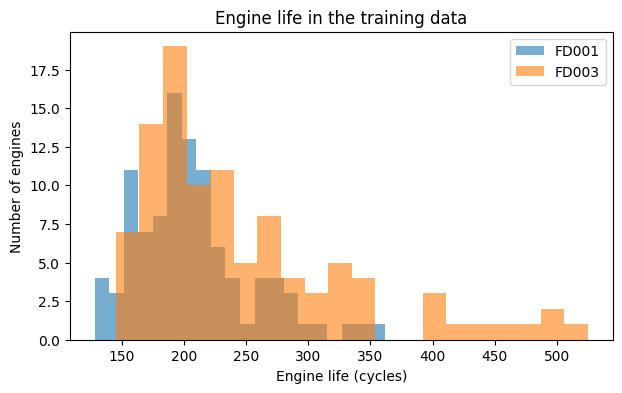

In [ ]:
engine_life = train.groupby(["dataset", "engine"])["max_cycle"].max().reset_index()
print(engine_life.groupby("dataset")["max_cycle"].describe().round(1))

plt.figure(figsize=(7, 4))
plt.hist(engine_life[engine_life["dataset"] == "FD001"]["max_cycle"], bins=20, alpha=0.6, label="FD001")
plt.hist(engine_life[engine_life["dataset"] == "FD003"]["max_cycle"], bins=20, alpha=0.6, label="FD003")
plt.xlabel("Engine life (cycles)")
plt.ylabel("Number of engines")
plt.title("Engine life in the training data")
plt.legend()
plt.show()

### 4.5 Distribution of RUL

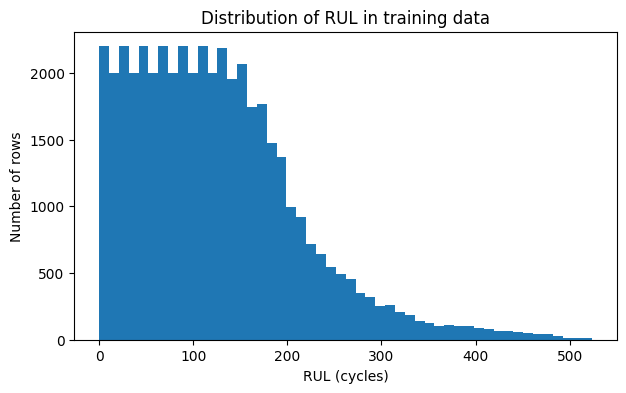

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(train["RUL"], bins=50)
plt.xlabel("RUL (cycles)")
plt.ylabel("Number of rows")
plt.title("Distribution of RUL in training data")
plt.show()

### 4.6 How do the sensors change as an engine gets close to failure?
I plot a few sensors for 5 random engines from each dataset. RUL goes down from left to right (failure at 0).

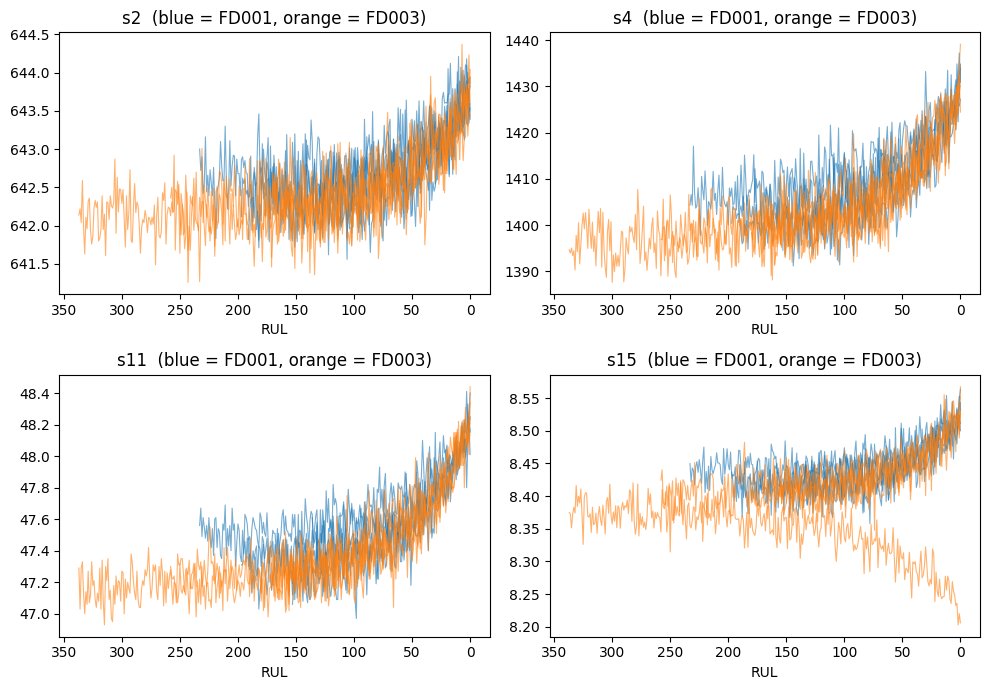

In [ ]:
some_engines = ["FD001_1", "FD001_20", "FD001_50", "FD001_70", "FD001_90",
                "FD003_1", "FD003_20", "FD003_50", "FD003_70", "FD003_90"]

sensors_to_plot = ["s2", "s4", "s11", "s15"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.flatten()

for i in range(len(sensors_to_plot)):
    s = sensors_to_plot[i]
    for e in some_engines:
        one_engine = train[train["engine"] == e]
        if e.startswith("FD001"):
            colour = "tab:blue"
        else:
            colour = "tab:orange"
        axes[i].plot(one_engine["RUL"], one_engine[s], color=colour, alpha=0.6, linewidth=0.8)
    axes[i].invert_xaxis()
    axes[i].set_title(s + "  (blue = FD001, orange = FD003)")
    axes[i].set_xlabel("RUL")

plt.tight_layout()
plt.show()

Most sensors go up or down steadily as the engine wears out. But for **s15** some FD003 engines go up and some go down.
This is because FD003 has **two different faults** (HPC and fan), and they push some sensors in opposite directions.

### 4.7 Correlation of each sensor with RUL

s11   -0.698
s4    -0.671
s17   -0.643
s13   -0.632
s8    -0.631
s3    -0.618
s2    -0.604
s9    -0.474
s14   -0.391
s20    0.258
s21    0.257
s15   -0.234
s12   -0.132
s7    -0.111
Name: RUL, dtype: float64


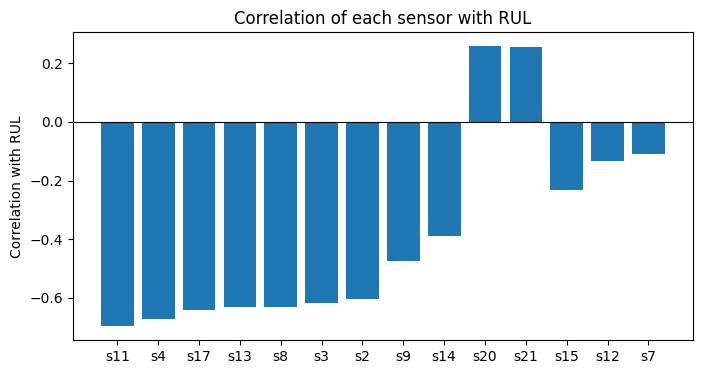

In [ ]:
correlations = train[useful_sensors + ["RUL"]].corr()["RUL"]
correlations = correlations.drop("RUL")
correlations = correlations.sort_values(key=abs, ascending=False)
print(correlations.round(3))

plt.figure(figsize=(8, 4))
plt.bar(correlations.index, correlations.values)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Correlation with RUL")
plt.title("Correlation of each sensor with RUL")
plt.show()

## 5. Feature selection
The guidelines say to use around 10 features or fewer. I start from the sensors most correlated with RUL,
then check if any two chosen sensors are almost the same (correlation above 0.9). If they are, I keep only one.

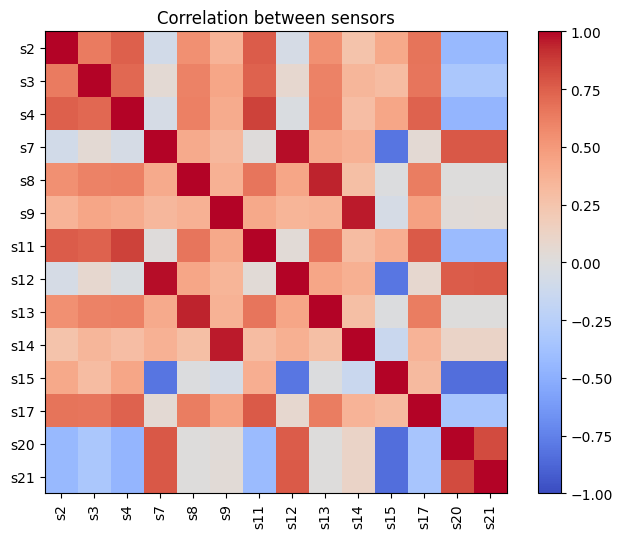

In [ ]:
plt.figure(figsize=(8, 6))
corr_matrix = train[useful_sensors].corr()
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(useful_sensors)), useful_sensors, rotation=90)
plt.yticks(range(len(useful_sensors)), useful_sensors)
plt.title("Correlation between sensors")
plt.show()

In [ ]:
chosen = []
for s in correlations.index:
    too_similar = False
    for c in chosen:
        if abs(corr_matrix.loc[s, c]) > 0.9:
            too_similar = True
            print(s, "dropped, too similar to", c, "(", round(corr_matrix.loc[s, c], 2), ")")
    if too_similar == False and len(chosen) < 10:
        chosen.append(s)

features = chosen
print()
print("Chosen features:", features)
print("Number of features:", len(features))

s8 dropped, too similar to s13 ( 0.94 )
s14 dropped, too similar to s9 ( 0.96 )

Chosen features: ['s11', 's4', 's17', 's13', 's3', 's2', 's9', 's20', 's21', 's15']
Number of features: 10


## 6. Preprocessing
### 6.1 Cap the RUL at 125
Early in its life an engine is healthy and the sensors do not show any wear, so the model can not tell
if it has 300 or 200 cycles left. Many papers cap RUL at around 125–130, so any RUL above 125 becomes 125.

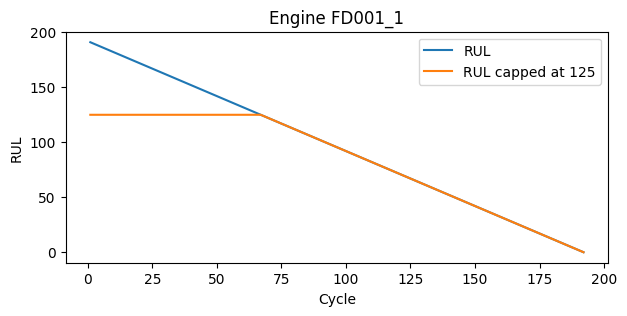

In [ ]:
train["RUL_capped"] = train["RUL"].clip(upper=125)
test["RUL_capped"] = test["RUL"].clip(upper=125)

plt.figure(figsize=(7, 3))
one = train[train["engine"] == "FD001_1"]
plt.plot(one["cycle"], one["RUL"], label="RUL")
plt.plot(one["cycle"], one["RUL_capped"], label="RUL capped at 125")
plt.xlabel("Cycle")
plt.ylabel("RUL")
plt.title("Engine FD001_1")
plt.legend()
plt.show()

### 6.2 Smooth the sensors
The sensor readings are noisy. I replace each reading with the average of the last 5 cycles of that engine
(a rolling mean), which makes the trend easier to see.

In [ ]:
for s in features:
    train[s] = train.groupby("engine")[s].transform(lambda x: x.rolling(5, min_periods=1).mean())
    test[s] = test.groupby("engine")[s].transform(lambda x: x.rolling(5, min_periods=1).mean())

one = train[train["engine"] == "FD001_1"]
print(one[["cycle", "s11"]].head(8))

   cycle     s11
0      1  47.470
1      2  47.480
2      3  47.410
3      4  47.340
4      5  47.328
5      6  47.266
6      7  47.240
7      8  47.234


### 6.3 Split training engines into train and validation
I split by **engine**, not by row. Rows from the same engine are very similar, so if some rows of an engine are in
training and others in validation, the model would look better than it really is.
80% of engines are used for training and 20% for validation (choosing the decision tree depth).

In [ ]:
all_engines = list(train["engine"].unique())

np.random.seed(42)
np.random.shuffle(all_engines)

n_train = int(len(all_engines) * 0.8)
train_engines = all_engines[:n_train]
val_engines = all_engines[n_train:]

train_part = train[train["engine"].isin(train_engines)]
val_part = train[train["engine"].isin(val_engines)]

print("Training engines:", len(train_engines), " rows:", len(train_part))
print("Validation engines:", len(val_engines), " rows:", len(val_part))

Training engines: 160  rows: 36557
Validation engines: 40  rows: 8794


### 6.4 Scale the features to 0–1
The sensors have very different ranges (one is around 47, another around 9000). MinMaxScaler puts all of them
between 0 and 1. The scaler is fitted on the training part only so no information from validation or test leaks in.

In [ ]:
scaler = MinMaxScaler()
scaler.fit(train_part[features])

X_train = scaler.transform(train_part[features])
X_val = scaler.transform(val_part[features])

y_train = train_part["RUL_capped"]
y_val = val_part["RUL_capped"]

print(X_train.shape, X_val.shape)

(36557, 10) (8794, 10)


### 6.5 The official test set
NASA's test engines stop some time before failure. Like in the papers, I predict the RUL at the **last cycle**
of each test engine and compare with the true RUL file.

In [ ]:
test_last = test.groupby("engine").tail(1)
X_test = scaler.transform(test_last[features])
y_test = test_last["RUL_capped"]

print("Test engines:", len(test_last))

Test engines: 200


## 7. Baseline model
The simplest possible model: always predict the average RUL of the training data.
Any real model has to be better than this.

In [ ]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

mean_rul = y_train.mean()
print("Average RUL in training data:", round(mean_rul, 2))

baseline_val = np.full(len(y_val), mean_rul)
print("Baseline validation RMSE:", round(rmse(y_val, baseline_val), 2))

Average RUL in training data: 90.53
Baseline validation RMSE: 41.42


## 8. Linear regression
Linear regression finds a weight for each sensor so that RUL = w1·s2 + w2·s3 + ... + b fits the data best.

In [ ]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

lin_val_pred = lin_model.predict(X_val)
print("Linear regression validation RMSE:", round(rmse(y_val, lin_val_pred), 2))

coef_table = pd.DataFrame({"feature": features, "weight": lin_model.coef_})
print(coef_table.round(2))

Linear regression validation RMSE: 21.45
  feature  weight
0     s11  -76.71
1      s4  -52.04
2     s17  -22.01
3     s13   43.06
4      s3  -26.74
5      s2  -32.96
6      s9  -74.20
7     s20   30.96
8     s21   22.89
9     s15   82.72


## 9. Decision tree (regression)
A decision tree asks yes/no questions about the sensors (for example "is s11 > 0.6?") and ends at a leaf
that gives a predicted RUL. Unlike linear regression it can learn curved (non-linear) patterns,
for example wear speeding up near the end of life.

The most important setting is max_depth (how many questions deep the tree can go). A tree that is too deep
memorises the training data (overfitting). I try depths 2 to 15 and pick the one with the lowest validation RMSE.

In [ ]:
depths = range(2, 16)
train_scores = []
val_scores = []

for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=42)
    tree.fit(X_train, y_train)
    train_scores.append(rmse(y_train, tree.predict(X_train)))
    val_scores.append(rmse(y_val, tree.predict(X_val)))
    print("depth", d, " train RMSE", round(train_scores[-1], 2), " validation RMSE", round(val_scores[-1], 2))

best_depth = depths[np.argmin(val_scores)]
print()
print("Best depth:", best_depth)

depth 2  train RMSE 21.54  validation RMSE 23.39
depth 3  train RMSE 19.34  validation RMSE 21.38
depth 4  train RMSE 18.21  validation RMSE 20.42
depth 5  train RMSE 17.45  validation RMSE 19.84
depth 6  train RMSE 16.94  validation RMSE 19.9
depth 7  train RMSE 16.47  validation RMSE 19.59
depth 8  train RMSE 16.0  validation RMSE 19.48
depth 9  train RMSE 15.48  validation RMSE 19.38
depth 10  train RMSE 14.88  validation RMSE 19.88
depth 11  train RMSE 14.17  validation RMSE 20.38
depth 12  train RMSE 13.4  validation RMSE 20.99
depth 13  train RMSE 12.55  validation RMSE 21.52
depth 14  train RMSE 11.6  validation RMSE 22.19
depth 15  train RMSE 10.67  validation RMSE 22.73

Best depth: 9


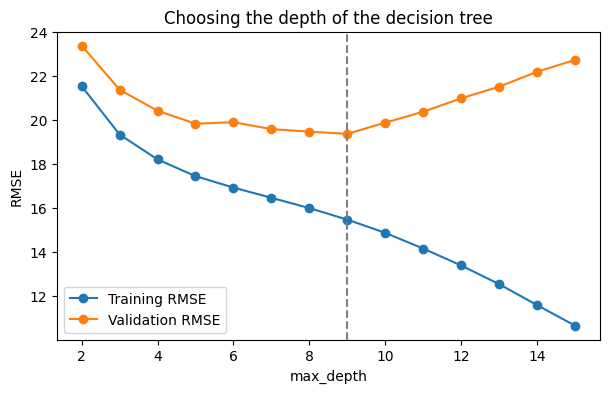

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(depths, train_scores, marker="o", label="Training RMSE")
plt.plot(depths, val_scores, marker="o", label="Validation RMSE")
plt.axvline(best_depth, color="grey", linestyle="--")
plt.xlabel("max_depth")
plt.ylabel("RMSE")
plt.title("Choosing the depth of the decision tree")
plt.legend()
plt.show()

Training error keeps going down as the tree gets deeper, but validation error stops improving and then goes up.
That is overfitting. I use the best depth.

## 10. Final models on the official test set
Now I retrain each model on **all** 200 training engines (train + validation) and test once on the NASA test engines.

In [ ]:
scaler_all = MinMaxScaler()
scaler_all.fit(train[features])
X_all = scaler_all.transform(train[features])
y_all = train["RUL_capped"]
X_test = scaler_all.transform(test_last[features])

# baseline
base_pred = np.full(len(y_test), y_all.mean())

# linear regression
lin_model = LinearRegression()
lin_model.fit(X_all, y_all)
lin_pred = lin_model.predict(X_test)
lin_pred = np.clip(lin_pred, 0, 125)

# decision tree
tree_model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
tree_model.fit(X_all, y_all)
tree_pred = tree_model.predict(X_test)

In [ ]:
results = []
for name, pred in [("Mean baseline", base_pred), ("Linear regression", lin_pred), ("Decision tree", tree_pred)]:
    for ds in ["FD001", "FD003"]:
        mask = (test_last["dataset"] == ds).values
        results.append({"model": name, "dataset": ds,
                        "RMSE": round(rmse(y_test[mask], pred[mask]), 2),
                        "MAE": round(mean_absolute_error(y_test[mask], pred[mask]), 2)})
    results.append({"model": name, "dataset": "Both",
                    "RMSE": round(rmse(y_test, pred), 2),
                    "MAE": round(mean_absolute_error(y_test, pred), 2)})

results_table = pd.DataFrame(results)
results_table

,model,dataset,RMSE,MAE
0,Mean baseline,FD001,43.08,34.93
1,Mean baseline,FD003,42.50,35.67
2,Mean baseline,Both,42.79,35.30
3,Linear regression,FD001,21.12,17.27
4,Linear regression,FD003,21.09,16.09
5,Linear regression,Both,21.10,16.68
6,Decision tree,FD001,18.29,13.09
7,Decision tree,FD003,19.95,13.50
8,Decision tree,Both,19.14,13.30


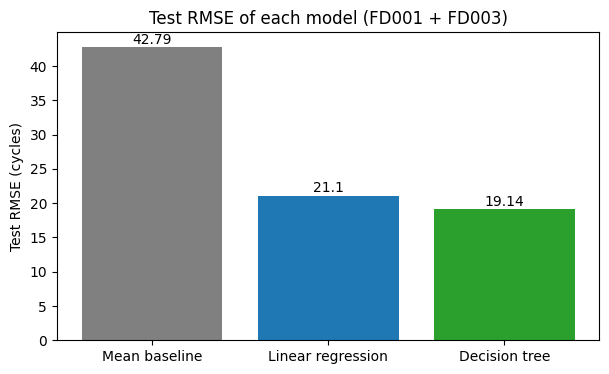

In [ ]:
plt.figure(figsize=(7, 4))
both = results_table[results_table["dataset"] == "Both"]
plt.bar(both["model"], both["RMSE"], color=["grey", "tab:blue", "tab:green"])
for i in range(len(both)):
    plt.text(i, both["RMSE"].values[i] + 0.5, str(both["RMSE"].values[i]), ha="center")
plt.ylabel("Test RMSE (cycles)")
plt.title("Test RMSE of each model (FD001 + FD003)")
plt.show()

## 11. Which sensors does the decision tree use most?

  feature  importance
0     s11       0.798
6      s9       0.153
1      s4       0.015
9     s15       0.012
3     s13       0.005
5      s2       0.005
4      s3       0.004
8     s21       0.003
7     s20       0.002
2     s17       0.001


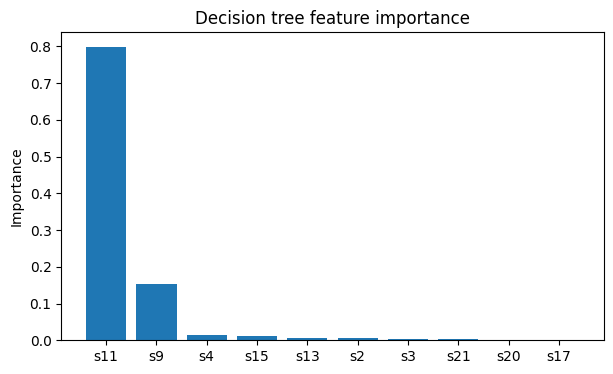

In [ ]:
importance = pd.DataFrame({"feature": features, "importance": tree_model.feature_importances_})
importance = importance.sort_values("importance", ascending=False)
print(importance.round(3))

plt.figure(figsize=(7, 4))
plt.bar(importance["feature"], importance["importance"])
plt.ylabel("Importance")
plt.title("Decision tree feature importance")
plt.show()

## 12. Logistic regression: will the engine fail in the next 30 cycles?
Here the target is 1 if RUL ≤ 30, otherwise 0. Logistic regression gives a probability between 0 and 1;
if it is above 0.5 the engine is flagged as "at risk".
I test it on **every row** of the test engines, not just the last one, so there are more at-risk examples.

In [ ]:
train["fail_soon"] = (train["RUL"] <= 30).astype(int)
test["fail_soon"] = (test["RUL"] <= 30).astype(int)

print("Share of training rows that fail soon:", round(train["fail_soon"].mean() * 100, 1), "%")

X_test_rows = scaler_all.transform(test[features])

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_all, train["fail_soon"])

risk_pred = log_model.predict(X_test_rows)
y_risk = test["fail_soon"]

print("Accuracy :", round(accuracy_score(y_risk, risk_pred), 3))
print("Precision:", round(precision_score(y_risk, risk_pred), 3))
print("Recall   :", round(recall_score(y_risk, risk_pred), 3))
print("F1 score :", round(f1_score(y_risk, risk_pred), 3))

Share of training rows that fail soon: 13.7 %
Accuracy : 0.989
Precision: 0.813
Recall   : 0.613
F1 score : 0.699


[[28981    88]
 [  241   382]]


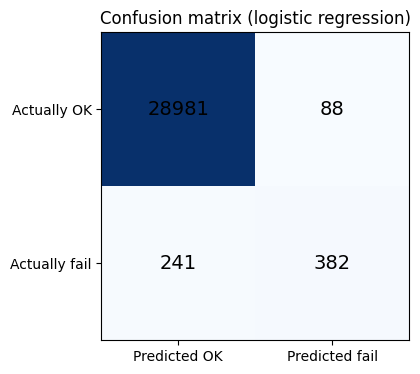

In [ ]:
cm = confusion_matrix(y_risk, risk_pred)
print(cm)

plt.figure(figsize=(4, 4))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
plt.xticks([0, 1], ["Predicted OK", "Predicted fail"])
plt.yticks([0, 1], ["Actually OK", "Actually fail"])
plt.title("Confusion matrix (logistic regression)")
plt.show()

Accuracy is high mostly because most rows are "OK". Precision and recall tell us more:
- **Precision**: of the engines we flagged, how many really failed soon.
- **Recall**: of the engines that really failed soon, how many we caught.

## 13. Error analysis
### 13.1 Predicted vs true RUL (decision tree)

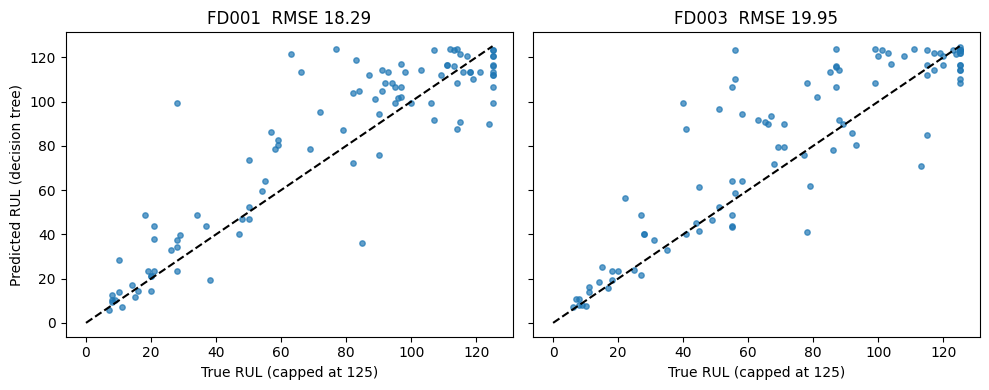

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for i, ds in enumerate(["FD001", "FD003"]):
    mask = (test_last["dataset"] == ds).values
    axes[i].scatter(y_test[mask], tree_pred[mask], s=15, alpha=0.7)
    axes[i].plot([0, 125], [0, 125], "k--")
    axes[i].set_title(ds + "  RMSE " + str(round(rmse(y_test[mask], tree_pred[mask]), 2)))
    axes[i].set_xlabel("True RUL (capped at 125)")
axes[0].set_ylabel("Predicted RUL (decision tree)")
plt.tight_layout()
plt.show()

### 13.2 Is the error bigger for some engines?
I group the test engines by how much life they really had left.

         count   mean   RMSE
band                        
0-25        34   4.96  10.36
25-50       25  10.20  22.66
50-75       33  20.06  28.33
75-100      41  10.67  21.72
100-125     67  -3.33  12.78


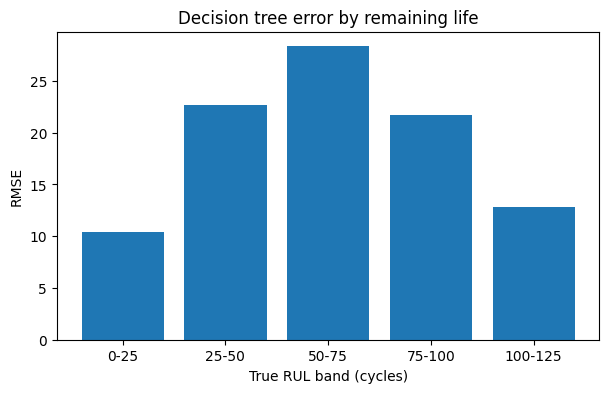

In [ ]:
errors = pd.DataFrame({"dataset": test_last["dataset"].values,
                       "true_RUL": y_test.values,
                       "predicted": tree_pred})
errors["error"] = errors["predicted"] - errors["true_RUL"]

errors["band"] = pd.cut(errors["true_RUL"], bins=[0, 25, 50, 75, 100, 126],
                        labels=["0-25", "25-50", "50-75", "75-100", "100-125"], right=False)

band_table = errors.groupby("band", observed=True)["error"].agg(["count", "mean"])
band_table["RMSE"] = errors.groupby("band", observed=True)["error"].apply(lambda e: np.sqrt((e ** 2).mean()))
print(band_table.round(2))

plt.figure(figsize=(7, 4))
plt.bar(band_table.index.astype(str), band_table["RMSE"])
plt.xlabel("True RUL band (cycles)")
plt.ylabel("RMSE")
plt.title("Decision tree error by remaining life")
plt.show()

### 13.3 Early or late predictions?
A **late** prediction (predicted RUL bigger than the real RUL) is dangerous because maintenance would happen too late.

In [ ]:
late = (errors["error"] > 10).sum()
early = (errors["error"] < -10).sum()
close = (errors["error"].abs() <= 10).sum()

print("Predictions within 10 cycles:", close)
print("More than 10 cycles too late:", late)
print("More than 10 cycles too early:", early)

print()
print("5 worst engines:")
worst = errors.copy()
worst["engine"] = test_last["engine"].values
worst["abs_error"] = worst["error"].abs()
print(worst.sort_values("abs_error", ascending=False).head(5)[["engine", "true_RUL", "predicted", "error"]].round(1))

Predictions within 10 cycles: 110
More than 10 cycles too late: 67
More than 10 cycles too early: 23

5 worst engines:
       engine  true_RUL  predicted  error
17   FD001_18        28       99.2   71.2
115  FD003_16        56      123.2   67.2
157  FD003_58        40       99.2   59.2
78   FD001_79        63      121.6   58.6
184  FD003_85        56      110.1   54.1


## 14. Save results for the report

In [ ]:
results_table.to_csv("results_table.csv", index=False)
band_table.to_csv("error_by_band.csv")
print("Saved")

Saved


## 15. Save the models for the maintenance system
The final scaler, decision tree and logistic regression are saved in the `models` folder.
`predictor.py` loads these files, so the simulation, agents and ERP use the models built in this notebook.

In [ ]:
import os, pickle

# the maintenance system's models folder
models_dir = "models"
os.makedirs(models_dir, exist_ok=True)

# save the final models
pickle.dump(scaler_all, open(os.path.join(models_dir, "scaler.pkl"), "wb"))
pickle.dump(tree_model, open(os.path.join(models_dir, "rul_model.pkl"), "wb"))
pickle.dump(log_model, open(os.path.join(models_dir, "risk_model.pkl"), "wb"))

print("Models saved to:", models_dir)
print("Features in order:", features)

Models saved to: models
Features in order: ['s11', 's4', 's17', 's13', 's3', 's2', 's9', 's20', 's21', 's15']


## 16. Store the data in the ERP
1. Make a fresh ERP database (`erp.db`). This is done only once here, so nothing gets wiped later.
2. Save the test predictions of the decision tree and linear regression for all 200 test engines.
3. Run the simulation: 10 engines, 1 cycle = 1 day. When an engine's risk reaches 0.7 the agents act,
   and everything they do (work orders, purchase requisitions, invoices, audit log) is stored through `erp.py`.

In [ ]:
import sys, os
sys.path.insert(0, os.getcwd())   # so Python finds erp.py and the other files in this folder

import erp
import run_simulation

# 1. fresh database
erp.create_database()

# 2. the 200 test engines: name, true RUL, tree prediction, linear regression prediction
erp.save_model_predictions(test_last["engine"].values, y_test.values, tree_pred, lin_pred)
print("Saved predictions for", len(test_last), "test engines")

# 3. run the simulation (the agents write into the ERP)
run_simulation.run_simulation()

print()
print("Invoices waiting for a reviewer:", len(erp.get_pending_invoices()))
print("Requisitions waiting for approval:", len(erp.get_pending_requisitions()))

Saved predictions for 200 test engines
Engines in the fleet: ['FD001_34', 'FD001_31', 'FD001_81', 'FD001_68', 'FD001_82', 'FD001_76', 'FD001_42', 'FD001_35', 'FD001_66', 'FD001_56']
Day 129 - FD001_56 risk 0.74 RUL 14.3 -> agents act
Day 138 - FD001_66 risk 0.796 RUL 28.6 -> agents act
Day 159 - FD001_82 risk 0.769 RUL 21.7 -> agents act
Day 170 - FD001_35 risk 0.7 RUL 33.0 -> agents act
Day 174 - FD001_68 risk 0.788 RUL 25.4 -> agents act
Day 179 - FD001_31 risk 0.757 RUL 27.8 -> agents act
Day 193 - FD001_76 risk 0.708 RUL 23.9 -> agents act
Day 194 - FD001_81 risk 0.781 RUL 20.5 -> agents act
Day 198 - FD001_34 risk 0.793 RUL 14.3 -> agents act

Simulation finished after 213 days
Engines that raised an alert: 9 of 10

Invoices waiting for a reviewer: 4
Requisitions waiting for approval: 2


## 17. Open the dashboard
This starts the small web server (`app.py`) in the background and gives you a link.
Click it and the dashboard opens in a **new tab**. There you can approve invoices, and each
approved invoice opens as a printable page. If nothing opens, copy the printed address into a new tab.
On your own computer, open http://127.0.0.1:5000 instead.

In [ ]:
import subprocess, sys, time

# start app.py in the background (it keeps running while this notebook is open)
server = subprocess.Popen([sys.executable, "app.py"])
time.sleep(3)

try:
    from google.colab import output
    output.serve_kernel_port_as_window(5000, anchor_text="Open the dashboard in a new tab")
    print("Backup link:", output.eval_js("google.colab.kernel.proxyPort(5000)"))
except ImportError:
    print("Open the dashboard here: http://127.0.0.1:5000")

# to stop the server later, run:  server.terminate()